# Task 54: Manual LIME Explanations

Sample local feature perturbations, fit a distance-weighted ridge surrogate manually, and verify explanation fidelity on independent perturbations.

Model probability: 0.8992 local surrogate: 0.905
Independent perturbation weighted R2: 0.9549


,Feature,Standardized value,Coefficient,Contribution at case
1,sex,-1.4186,-0.1198,0.1700
11,ca,-0.7028,-0.1316,0.0925
2,cp,1.0364,0.0851,0.0882
12,thal,1.2101,-0.0700,-0.0847
10,slope,0.9780,0.0762,0.0745
9,oldpeak,-0.7321,-0.0901,0.0659
7,thalach,-0.6886,0.0873,-0.0601
8,exang,-0.6918,-0.0815,0.0564
4,chol,1.2404,-0.0241,-0.0299
6,restecg,0.9263,0.0245,0.0227


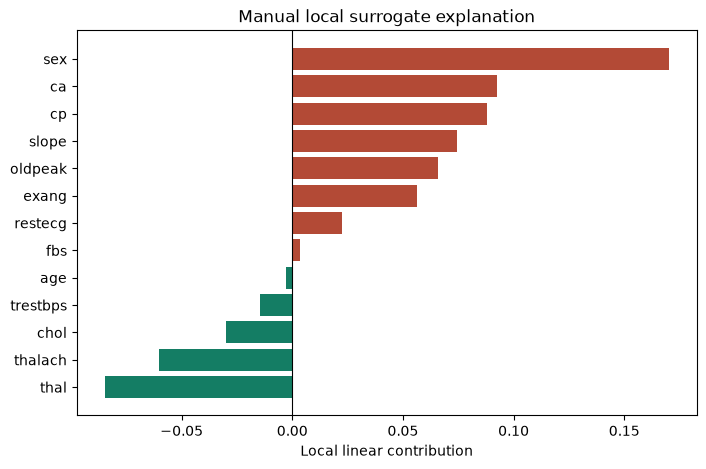

Verification perturbations use an independent random seed. High surrogate fidelity is local approximation quality, not proof that the classifier is correct.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

paths=[Path('heart.csv'),Path('Task_54_Manual_LIME_Explanations/heart.csv'),Path('Heart_Disease_Tasks/Task_54_Manual_LIME_Explanations/heart.csv')]
data=pd.read_csv(next(p for p in paths if p.is_file())).drop_duplicates().reset_index(drop=True)
features=[c for c in ['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak','slope','ca','thal'] if c in data]
X,y=data[features].to_numpy(float),data.target.to_numpy(int)
def split(labels,fraction,seed):
    rng=np.random.default_rng(seed);a=[];b=[]
    for label in np.unique(labels):
        ids=np.flatnonzero(labels==label);rng.shuffle(ids);cut=round(fraction*len(ids));a.extend(ids[:cut]);b.extend(ids[cut:])
    rng.shuffle(a);rng.shuffle(b);return np.array(a),np.array(b)
train,test=split(y,.8,54);Xtr,Xte=X[train],X[test];ytr,yte=y[train],y[test]
mean,scale=Xtr.mean(0),Xtr.std(0);scale[scale==0]=1;Xtr,Xte=(Xtr-mean)/scale,(Xte-mean)/scale
class Logistic:
    def fit(self,x,y):
        self.w=np.zeros(x.shape[1]);self.b=0.
        for _ in range(1200):
            p=1/(1+np.exp(-np.clip(x@self.w+self.b,-35,35)));e=p-y;self.w-=.06*(x.T@e/len(y)+.02*self.w);self.b-=.06*e.mean()
        return self
    def proba(self,x):return 1/(1+np.exp(-np.clip(x@self.w+self.b,-35,35)))
model=Logistic().fit(Xtr,ytr)


def perturb(instance,background,count,seed):
    rng=np.random.default_rng(seed);indices=rng.integers(0,len(background),size=(count,len(instance)))
    samples=background[indices,np.arange(len(instance))[None,:]];samples[0]=instance
    return samples

def kernel_weights(samples,instance,width):
    distance=np.sqrt(np.mean((samples-instance)**2,axis=1))
    return np.exp(-(distance**2)/(width**2))

def weighted_ridge(samples,target,weights,ridge=.01):
    design=np.column_stack([np.ones(len(samples)),samples]);sqrtw=np.sqrt(weights)
    gram=(design*sqrtw[:,None]).T@(design*sqrtw[:,None]);penalty=np.eye(gram.shape[0])*ridge;penalty[0,0]=0
    beta=np.linalg.solve(gram+penalty,(design*sqrtw[:,None]).T@(target*sqrtw))
    return beta[0],beta[1:]
def weighted_r2(actual,predicted,weights):
    average=np.average(actual,weights=weights);res=np.sum(weights*(actual-predicted)**2);total=np.sum(weights*(actual-average)**2)
    return 1-res/total if total>1e-12 else 1.

instance=Xte[0];samples=perturb(instance,Xtr,1500,540);targets=model.proba(samples);weights=kernel_weights(samples,instance,.75)
intercept,coefficients=weighted_ridge(samples,targets,weights)
verification=perturb(instance,Xtr,700,1540);verification_targets=model.proba(verification);verification_weights=kernel_weights(verification,instance,.75)
verification_predictions=intercept+verification@coefficients
model_value=float(model.proba(instance[None,:])[0]);surrogate_value=float(intercept+instance@coefficients)
print('Model probability:',round(model_value,4),'local surrogate:',round(surrogate_value,4))
print('Independent perturbation weighted R2:',round(weighted_r2(verification_targets,verification_predictions,verification_weights),4))
local=pd.DataFrame({'Feature':features,'Standardized value':instance,'Coefficient':coefficients,'Contribution at case':coefficients*instance}).sort_values('Contribution at case',key=np.abs,ascending=False)
display(local.round(4))
plot=local.sort_values('Contribution at case');fig,ax=plt.subplots(figsize=(8,5))
ax.barh(plot['Feature'],plot['Contribution at case'],color=np.where(plot['Contribution at case']>=0,'#b34a36','#147d64'));ax.axvline(0,color='black',linewidth=.8)
ax.set_xlabel('Local linear contribution');ax.set_title('Manual local surrogate explanation');plt.show()
print('Verification perturbations use an independent random seed. High surrogate fidelity is local approximation quality, not proof that the classifier is correct.')